In [ ]:
# IMPORTS & DATA CLEANING (USDA TABLE 14 + TABLE 18 -> MONTHLY YYYY-MM)
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.regression.linear_model import yule_walker
import statsmodels.api as sm

warnings.filterwarnings("ignore")

# Read USDA workbook (calamine engine bypasses USDA's malformed XML stylesheet)
t14_raw = pd.read_excel("wheat_data.xlsx", sheet_name="Table14", engine="calamine", header=None)
t18_raw = pd.read_excel("wheat_data.xlsx", sheet_name="Table18", engine="calamine", header=None)

months_list = ['Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May']
m_map = {'Jun': 6, 'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12,
         'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5}

def marketing_year_to_date(my_str, month_str):
    start_year = int(str(my_str).split('/')[0])
    month_num = m_map[month_str]
    cal_year = start_year if month_num >= 6 else start_year + 1
    return pd.Timestamp(year=cal_year, month=month_num, day=1)

# Clean Table 14 (Wheat Ground for Flour, 1,000 bushels)
t14 = t14_raw.iloc[2:].copy()
t14.columns = ['MY', 'Month', 'Wheat_Ground', 'Food_Imports', 'Nonmilled_Food', 'Food_Exports', 'Food_Use']
t14 = t14[t14['Month'].isin(months_list)].copy()
t14['Date'] = [marketing_year_to_date(my, m) for my, m in zip(t14['MY'], t14['Month'])]
t14['Month_Year'] = t14['Date'].dt.strftime('%Y-%m')
t14['Wheat_Ground'] = pd.to_numeric(t14['Wheat_Ground'], errors='coerce')
t14_clean = t14[['Date', 'Month_Year', 'Wheat_Ground']].dropna().sort_values('Date')

# Clean Table 18 (All Wheat Farm Price Received, $/bushel)
t18 = t18_raw.copy()
t18.columns = t18.iloc[1].tolist()
t18_aw = t18[t18['Class'] == 'All wheat'].copy()

price_rows = []
for _, row in t18_aw.iterrows():
    my = row['Marketing year 1/']
    if pd.notna(my) and '/' in str(my):
        for m in months_list:
            val = pd.to_numeric(row[m], errors='coerce')
            if pd.notna(val):
                dt = marketing_year_to_date(my, m)
                price_rows.append({'Date': dt, 'Month_Year': dt.strftime('%Y-%m'), 'Farm_Price': val})
t18_clean = pd.DataFrame(price_rows).sort_values('Date')

# Merge & verify zero missing/duplicate months
df = pd.merge(t14_clean, t18_clean, on=['Date', 'Month_Year'], how='inner')
expected = pd.date_range(df['Date'].min(), df['Date'].max(), freq='MS')
assert len(expected.difference(df['Date'])) == 0, "Missing months found!"
assert df['Date'].duplicated().sum() == 0, "Duplicate months found!"

with pd.ExcelWriter("cleaned_wheat_monthly.xlsx", engine="openpyxl") as writer:
    df.drop(columns=['Date']).to_excel(writer, sheet_name="Merged_Monthly", index=False)

df = df.set_index('Date').asfreq('MS')
print(f"Clean dataset ready: {len(df)} months ({df['Month_Year'].min()} to {df['Month_Year'].max()}), 0 missing.")
display(df.head())

Clean dataset ready: 448 months (1989-06 to 2026-09), 0 missing.


,Month_Year,Wheat_Ground,Farm_Price
Date,,,
1989-06-01,1989-06,58353.0,3.85
1989-07-01,1989-07,60756.0,3.78
1989-08-01,1989-08,73871.0,3.74
1989-09-01,1989-09,66326.0,3.72
1989-10-01,1989-10,70481.0,3.75


Box-Cox MLE lambda_P = -0.2737 (~ 0 -> ln(P_t))
Box-Cox MLE lambda_Q = 3.2450 (-> (Q_t^lambda - 1)/lambda, standardized)


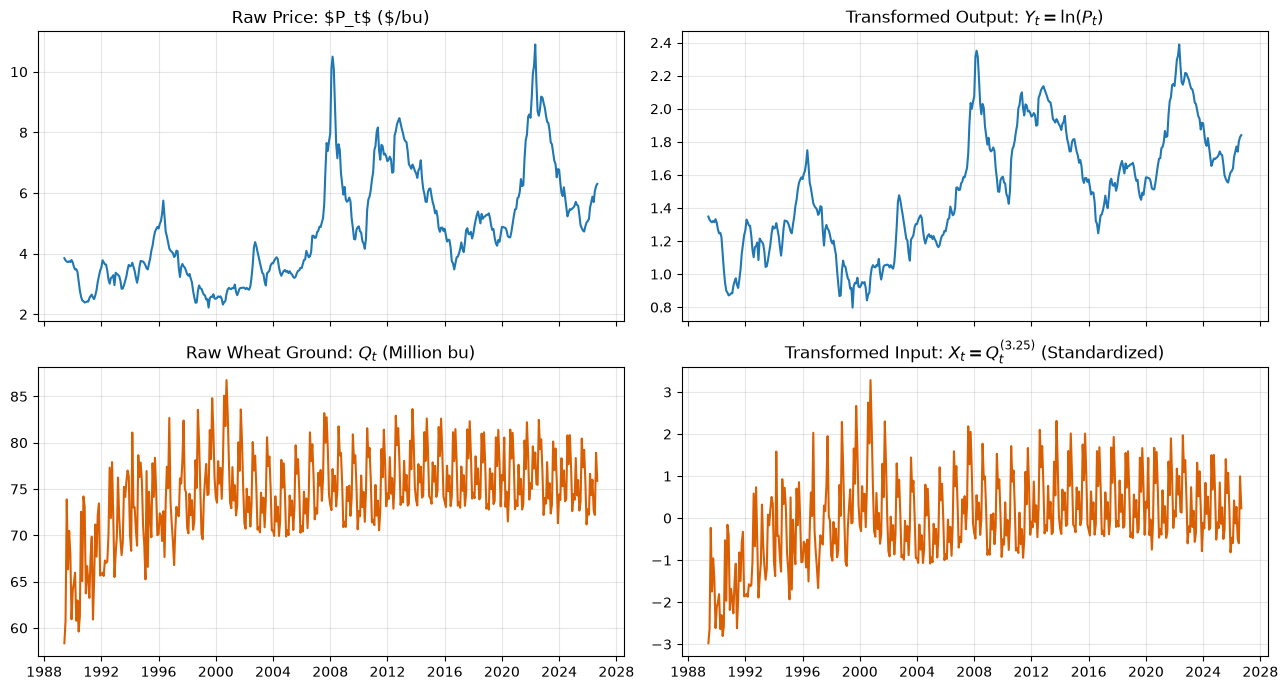

In [ ]:
# RAW SERIES PLOTS & BOX-COX VARIANCE STABILIZING TRANSFORMATIONS
df["Q_million"] = df["Wheat_Ground"] / 1000.0  # Million bushels

# Estimate Box-Cox power parameters
_, lam_P = boxcox(df["Farm_Price"])
Q_bc_raw, lam_Q = boxcox(df["Q_million"])
print(f"Box-Cox MLE lambda_P = {lam_P:.4f} (~ 0 -> ln(P_t))")
print(f"Box-Cox MLE lambda_Q = {lam_Q:.4f} (-> (Q_t^lambda - 1)/lambda, standardized)")

# Apply course Box-Cox transformations
df["Y_price"] = np.log(df["Farm_Price"])                       # Output series Y_t
df["X_ground"] = (Q_bc_raw - Q_bc_raw.mean()) / Q_bc_raw.std() # Standardized Input series X_t

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
axes[0, 0].plot(df.index, df["Farm_Price"], color="#1f77b4")
axes[0, 0].set_title("Raw Price: $P_t$ ($/bu)")
axes[0, 1].plot(df.index, df["Y_price"], color="#1f77b4")
axes[0, 1].set_title("Transformed Output: $Y_t = \\ln(P_t)$")

axes[1, 0].plot(df.index, df["Q_million"], color="#d95f02")
axes[1, 0].set_title("Raw Wheat Ground: $Q_t$ (Million bu)")
axes[1, 1].plot(df.index, df["X_ground"], color="#d95f02")
axes[1, 1].set_title(f"Transformed Input: $X_t = Q_t^{{({lam_Q:.2f})}}$ (Standardized)")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# SAS PROC ARIMA 'IDENTIFY' HELPER FUNCTION(4-PANEL PLOT + LJUNG-BOX + 3-CASE ADF)
def compute_iacf(series, nlags=36):
    s = series.dropna().values - series.dropna().mean()
    ar_order = max(nlags + 5, min(int(np.floor(len(s) / 3)), 45))
    rho, _ = yule_walker(s, order=ar_order, method="mle")
    psi = np.concatenate(([1.0], -rho))
    gamma = np.array([np.sum(psi[:len(psi) - k] * psi[k:]) for k in range(nlags + 1)])
    return gamma / gamma[0]

def sas_identify(series, name, nlags=24):
    s = series.dropna()
    n = len(s)
    band = 1.96 / np.sqrt(n)

    print("=" * 74)
    print(f"IDENTIFY STAGE: {name}  |  Mean={s.mean():.4f}, Std={s.std(ddof=1):.4f}, N={n}")
    print("=" * 74)

    # 1. White Noise Check (Lags 6, 12, 18, 24)
    lb = acorr_ljungbox(s, lags=[6, 12, 18, 24], return_df=True)
    lb.columns = ["ChiSq (Q)", "Pr > ChiSq"]
    print("\n[1] Autocorrelation Check for White Noise:")
    print(lb.to_string())

    # 2. ADF Unit Root Tests (Zero Mean, Single Mean, Trend)
    print("\n[2] Augmented Dickey-Fuller (ADF) Unit Root Tests:")
    for reg, label in [("n", "Zero Mean"), ("c", "Single Mean"), ("ct", "Trend")]:
        stat, pval, lags_used, *_ = adfuller(s, regression=reg, autolag="AIC")
        print(f"    {label:12s} | Lags={lags_used:2d} | Tau={stat:8.4f} | Pr < Tau = {pval:.4f}")

    # 3. 4-Panel Plot: Series, ACF, PACF, IACF
    lags = np.arange(nlags + 1)
    acf_v = acf(s, nlags=nlags, fft=False)
    pacf_v = pacf(s, nlags=nlags, method="ywm")
    iacf_v = compute_iacf(s, nlags=nlags)

    fig, axes = plt.subplots(2, 2, figsize=(12, 6.8))
    fig.suptitle(f"Trend and Correlation Analysis for {name}", fontsize=12, fontweight="bold")

    axes[0, 0].plot(s.index, s.values, color="#2b5c8f", lw=1.2)
    axes[0, 0].set_title("Working Series")

    axes[0, 1].bar(lags, acf_v, width=0.45, color="#4a77a8")
    axes[0, 1].axhspan(-band, band, color="#4a77a8", alpha=0.18)
    axes[0, 1].set_title("ACF")

    axes[1, 0].bar(lags[1:], pacf_v[1:], width=0.45, color="#4a77a8")
    axes[1, 0].axhspan(-band, band, color="#4a77a8", alpha=0.18)
    axes[1, 0].set_title("PACF")

    axes[1, 1].bar(lags, iacf_v, width=0.45, color="#4a77a8")
    axes[1, 1].axhspan(-band, band, color="#4a77a8", alpha=0.18)
    axes[1, 1].set_title("IACF")

    for ax in axes.flat:
        ax.axhline(0, color="black", lw=0.7)
        ax.grid(True, alpha=0.3)
    for ax in [axes[0, 1], axes[1, 0], axes[1, 1]]:
        ax.set_ylim(-1.05, 1.05)

    plt.tight_layout()
    plt.show()

IDENTIFY STAGE: Y_t = ln(Price) [Undifferentiated]  |  Mean=1.5054, Std=0.3633, N=448

[1] Autocorrelation Check for White Noise:
      ChiSq (Q)  Pr > ChiSq
6   2415.374840         0.0
12  4281.002992         0.0
18  5632.867894         0.0
24  6585.184938         0.0

[2] Augmented Dickey-Fuller (ADF) Unit Root Tests:
    Zero Mean    | Lags= 2 | Tau= -0.1111 | Pr < Tau = 0.6461
    Single Mean  | Lags= 2 | Tau= -1.9692 | Pr < Tau = 0.3002
    Trend        | Lags= 1 | Tau= -3.1287 | Pr < Tau = 0.0996


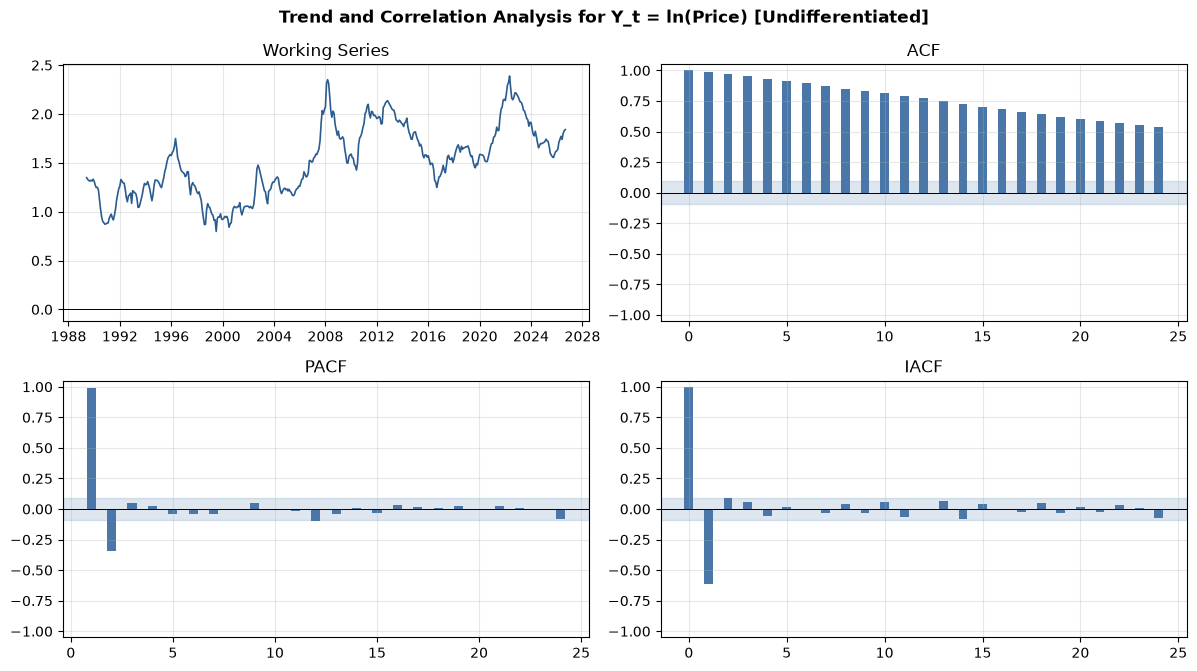

IDENTIFY STAGE: X_t = BoxCox(Wheat_Ground) [Undifferentiated]  |  Mean=-0.0000, Std=1.0011, N=448

[1] Autocorrelation Check for White Noise:
      ChiSq (Q)     Pr > ChiSq
6    308.455629   1.260777e-63
12   820.243999  7.533155e-168
18   982.548619  3.753754e-197
24  1331.060183  2.659927e-266

[2] Augmented Dickey-Fuller (ADF) Unit Root Tests:
    Zero Mean    | Lags=18 | Tau= -3.2325 | Pr < Tau = 0.0012
    Single Mean  | Lags=18 | Tau= -3.3394 | Pr < Tau = 0.0132
    Trend        | Lags=18 | Tau= -3.1753 | Pr < Tau = 0.0894


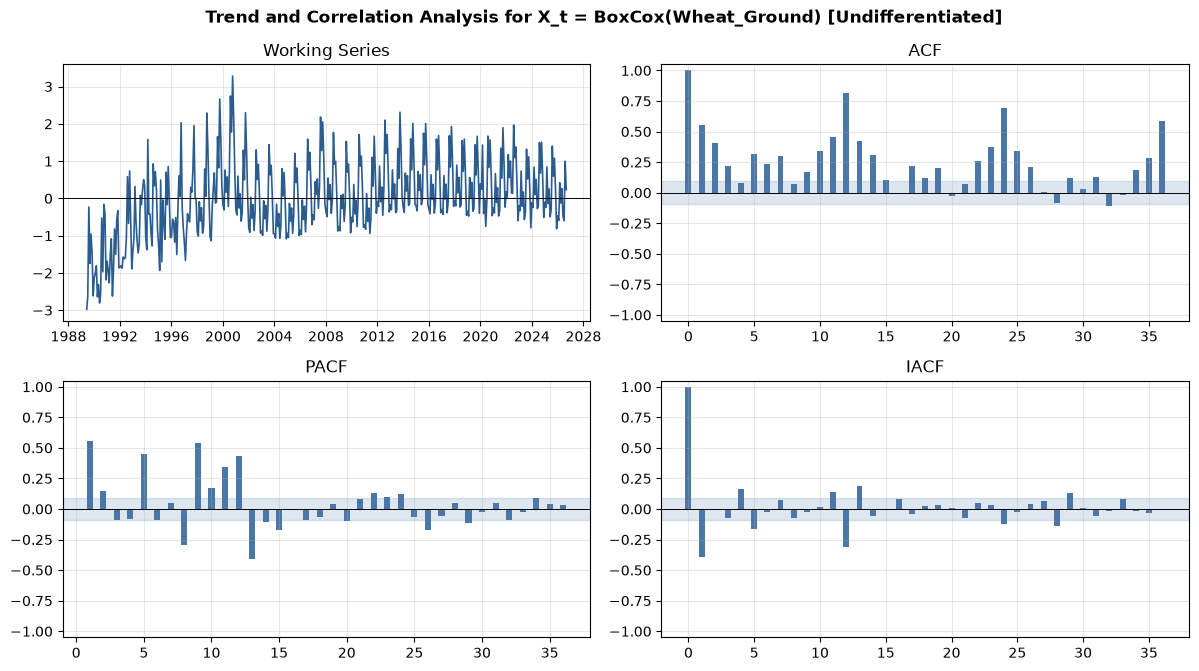

IDENTIFY STAGE: dY_t = (1 - B) ln(Price) [d=1]  |  Mean=0.0011, Std=0.0509, N=447

[1] Autocorrelation Check for White Noise:
    ChiSq (Q)    Pr > ChiSq
6   69.621294  4.889460e-13
12  80.419044  3.433312e-12
18  87.037640  4.892785e-11
24  96.988697  9.753669e-11

[2] Augmented Dickey-Fuller (ADF) Unit Root Tests:
    Zero Mean    | Lags= 1 | Tau=-12.7277 | Pr < Tau = 0.0000
    Single Mean  | Lags= 1 | Tau=-12.7201 | Pr < Tau = 0.0000
    Trend        | Lags= 1 | Tau=-12.7072 | Pr < Tau = 0.0000


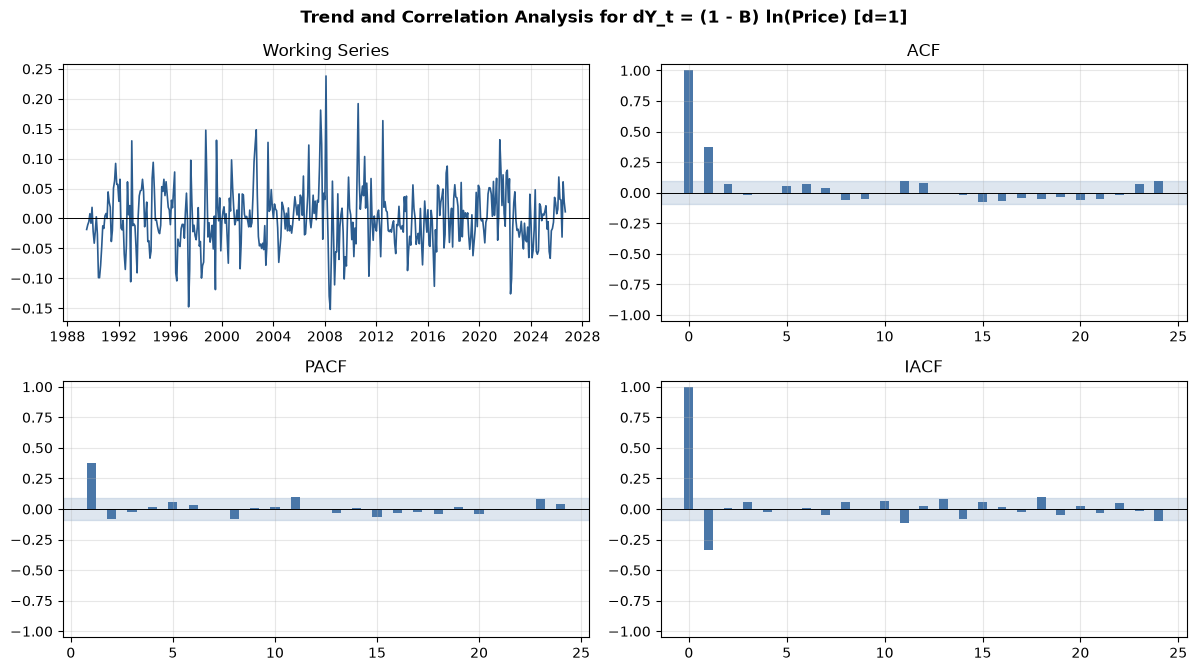

IDENTIFY STAGE: dX_t = (1 - B)(1 - B^12) BoxCox(Ground) [d=1, D=1]  |  Mean=-0.0012, Std=0.4839, N=435

[1] Autocorrelation Check for White Noise:
     ChiSq (Q)    Pr > ChiSq
6   102.744918  6.707469e-20
12  210.010684  2.783624e-38
18  263.533846  1.426468e-45
24  284.808050  1.892119e-46

[2] Augmented Dickey-Fuller (ADF) Unit Root Tests:
    Zero Mean    | Lags=15 | Tau= -8.6751 | Pr < Tau = 0.0000
    Single Mean  | Lags=15 | Tau= -8.6659 | Pr < Tau = 0.0000
    Trend        | Lags=15 | Tau= -8.6554 | Pr < Tau = 0.0000


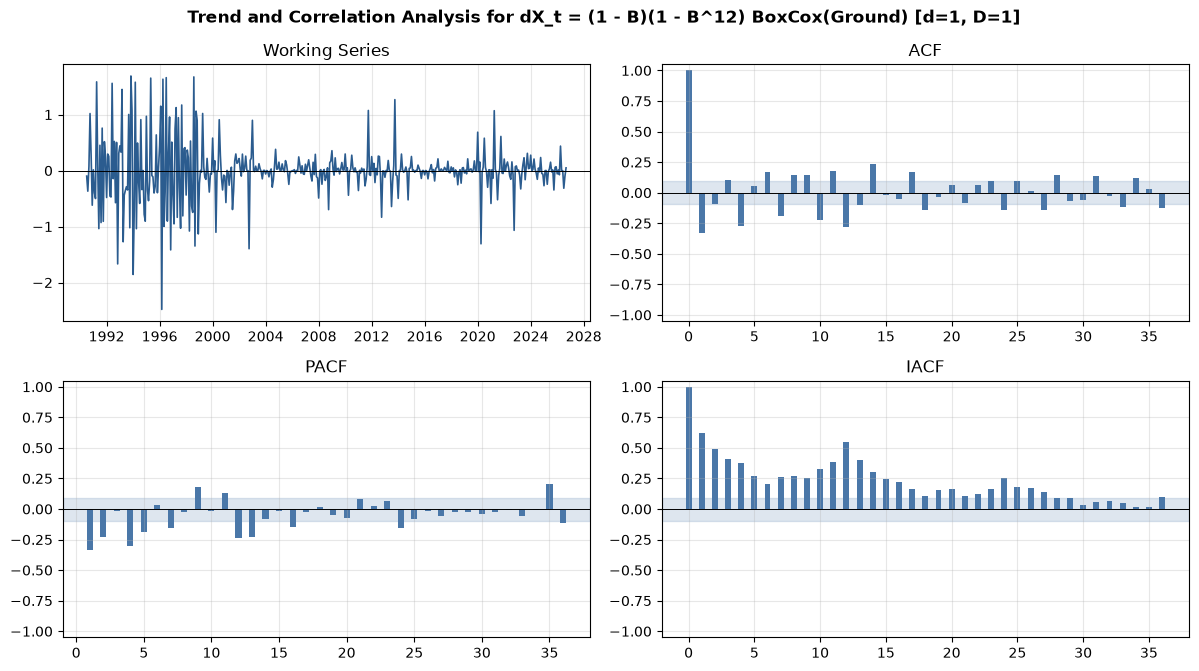

In [ ]:
# IDENTIFY BEFORE & AFTER DIFFERENCING (Y_t: d=1  |  X_t: d=1, D=1, s=12)

# Undifferentiated series (confirm unit roots)
sas_identify(df["Y_price"], "Y_t = ln(Price) [Undifferentiated]", nlags=24)
sas_identify(df["X_ground"], "X_t = BoxCox(Wheat_Ground) [Undifferentiated]", nlags=36)

# Differenced series (confirm stationarity & check IACF for over-differencing)
df["dY"] = df["Y_price"].diff(1)                 # Regular difference d=1
df["dX_1_12"] = df["X_ground"].diff(1).diff(12)  # Regular d=1 + Seasonal D=1 (s=12)

sas_identify(df["dY"], "dY_t = (1 - B) ln(Price) [d=1]", nlags=24)
sas_identify(df["dX_1_12"], "dX_t = (1 - B)(1 - B^12) BoxCox(Ground) [d=1, D=1]", nlags=36)

In [15]:
# ==============================================================================
# STEP 1 OF TRANSFER FUNCTION - FIT PRE-WHITENING MODEL FOR INPUT X_t
# ==============================================================================
candidates_X = [
    ("SARIMA(0,1,1)x(0,1,1,12)", (0, 1, 1), (0, 1, 1, 12)),
    ("SARIMA(1,1,1)x(0,1,1,12)", (1, 1, 1), (0, 1, 1, 12)),
    ("SARIMA(1,1,[1,2,4])x(1,1,1,12)", (1, 1, [1, 2, 4]), (1, 1, 1, 12)),
    ("SARIMA(1,1,[1,2,4,6])x(1,1,1,12)", (1, 1, [1, 2, 4, 6]), (1, 1, 1, 12)),
]

print("=== Candidate Seasonal ARIMA Models for Input X_t (Wheat Ground) ===")
fitted_X = {}
for label, order, sorder in candidates_X:
    res = sm.tsa.SARIMAX(df["X_ground"], order=order, seasonal_order=sorder).fit(disp=False)
    fitted_X[label] = res
    lb = acorr_ljungbox(res.resid.iloc[14:], lags=[6, 12, 24], return_df=True)
    pvals = ", ".join([f"Lag {k}: {p:.4f}" for k, p in zip(lb.index, lb["lb_pvalue"])])
    print(f"{label:34s} | AIC = {res.aic:7.2f} | BIC = {res.bic:7.2f} | LB White Noise -> {pvals}")

# Select the adequate white-noise model for pre-whitening X_t
best_X = fitted_X["SARIMA(1,1,[1,2,4,6])x(1,1,1,12)"]
print("\nSelected Input Model Summary:")
print(best_X.summary().tables[1])

=== Candidate Seasonal ARIMA Models for Input X_t (Wheat Ground) ===
SARIMA(0,1,1)x(0,1,1,12)           | AIC =  395.49 | BIC =  407.72 | LB White Noise -> Lag 6: 0.0000, Lag 12: 0.0000, Lag 24: 0.0000
SARIMA(1,1,1)x(0,1,1,12)           | AIC =  385.14 | BIC =  401.45 | LB White Noise -> Lag 6: 0.0000, Lag 12: 0.0000, Lag 24: 0.0000
SARIMA(1,1,[1,2,4])x(1,1,1,12)     | AIC =  347.88 | BIC =  376.40 | LB White Noise -> Lag 6: 0.0378, Lag 12: 0.0061, Lag 24: 0.0043
SARIMA(1,1,[1,2,4,6])x(1,1,1,12)   | AIC =  345.11 | BIC =  377.71 | LB White Noise -> Lag 6: 0.7732, Lag 12: 0.0877, Lag 24: 0.0661

Selected Input Model Summary:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3122      0.134     -2.338      0.019      -0.574      -0.050
ma.L1         -0.1963      0.122     -1.604      0.109      -0.436       0.044
ma.L2         -0.2966      0.085     -3.484      0.0

Pre-whitened CCF (N = 434, 95% Two-SE Limit = +/- 0.0941):
Lag k = -12: CCF = +0.0108
Lag k = -11: CCF = -0.0023
Lag k = -10: CCF = +0.0047
Lag k =  -9: CCF = -0.0166
Lag k =  -8: CCF = -0.0116
Lag k =  -7: CCF = -0.0333
Lag k =  -6: CCF = -0.0126
Lag k =  -5: CCF = +0.0001
Lag k =  -4: CCF = -0.0187
Lag k =  -3: CCF = -0.0805
Lag k =  -2: CCF = -0.0683
Lag k =  -1: CCF = -0.0007
Lag k =  +0: CCF = +0.0419
Lag k =  +1: CCF = +0.0303
Lag k =  +2: CCF = +0.0080
Lag k =  +3: CCF = +0.0455
Lag k =  +4: CCF = +0.0599
Lag k =  +5: CCF = +0.0848
Lag k =  +6: CCF = +0.0611
Lag k =  +7: CCF = +0.0524
Lag k =  +8: CCF = +0.0362
Lag k =  +9: CCF = +0.0969 <-- SIGNIFICANT
Lag k = +10: CCF = +0.0975 <-- SIGNIFICANT
Lag k = +11: CCF = +0.0643
Lag k = +12: CCF = +0.0252


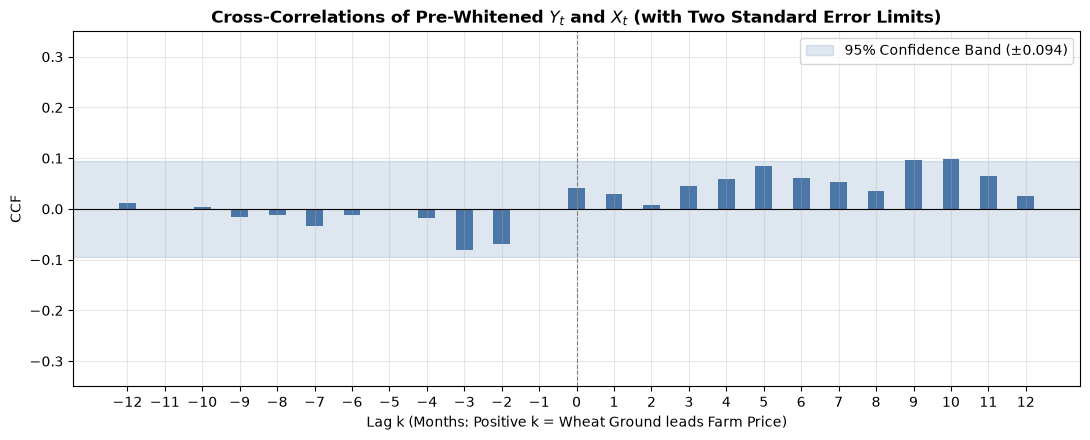

In [ ]:
# STEP 2 OF TRANSFER FUNCTION - PRE-WHITEN Y_t & COMPUTE CCF (b, r, s)

# alpha_t: pre-whitened input residuals (white noise)
alpha_t = best_X.resid.iloc[14:]

# Apply the EXACT same SARIMA filter of X_t to Y_price to get filtered output beta_t
filtered_Y_mod = sm.tsa.SARIMAX(
    df["Y_price"],
    order=(1, 1, [1, 2, 4, 6]),
    seasonal_order=(1, 1, 1, 12)
).filter(best_X.params)
beta_t = filtered_Y_mod.resid.iloc[14:]

# Compute sample cross-correlation rho_{alpha, beta}(k) for k = -12 to +12
# Note: positive lag k means X_{t-k} -> Y_t (input leads price)
lags_ccf = np.arange(-12, 13)
ccf_vals = []
for k in lags_ccf:
    if k < 0:
        ccf_vals.append(alpha_t.corr(beta_t.shift(-k)))
    elif k == 0:
        ccf_vals.append(alpha_t.corr(beta_t))
    else:
        ccf_vals.append(alpha_t.shift(k).corr(beta_t))

ccf_vals = np.array(ccf_vals)
se_limit = 1.96 / np.sqrt(len(alpha_t))

print(f"Pre-whitened CCF (N = {len(alpha_t)}, 95% Two-SE Limit = +/- {se_limit:.4f}):")
for k, r in zip(lags_ccf, ccf_vals):
    flag = " <-- SIGNIFICANT" if abs(r) > se_limit else ""
    print(f"Lag k = {k:+3d}: CCF = {r:+.4f}{flag}")

# Plot Pre-Whitened CCF (matching Slide 35 & Slide 50 of Transfer Function deck)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(lags_ccf, ccf_vals, width=0.45, color="#4a77a8")
ax.axhspan(-se_limit, se_limit, color="#4a77a8", alpha=0.18, label=f"95% Confidence Band (±{se_limit:.3f})")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="gray", lw=0.8, linestyle="--")
ax.set_title("Cross-Correlations of Pre-Whitened $Y_t$ and $X_t$ (with Two Standard Error Limits)", fontsize=12, fontweight="bold")
ax.set_xlabel("Lag k (Months: Positive k = Wheat Ground leads Farm Price)")
ax.set_ylabel("CCF")
ax.set_xticks(lags_ccf)
ax.set_ylim(-0.35, 0.35)
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== Model Comparison: Univariate ARIMA(1,1,0) vs. Transfer Function (b=9, s=1, r=0) ===
Univariate ARIMA(1,1,0)             | AIC = -1370.22 | BIC = -1362.12
Transfer Function (b=9, s=1, r=0)   | AIC = -1373.70 | BIC = -1357.49

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
dX_lag9        0.0060      0.005      1.274      0.203      -0.003       0.015
dX_lag10       0.0089      0.004      2.042      0.041       0.000       0.018
ar.L1          0.3624      0.039      9.191      0.000       0.285       0.440
sigma2         0.0023      0.000     21.190      0.000       0.002       0.002

[Diagnostic 1] Residual Autocorrelation Check for White Noise:
    ChiSq (Q)  Pr > ChiSq
6    5.656335    0.462766
12  17.077573    0.146702
18  18.561362    0.419288
24  26.859696    0.311036

[Diagnostic 2] Input-Residual Cross-Correlation Check (95% Band = +/- 0.0951):
Lag k =  0: CCF(alpha_t

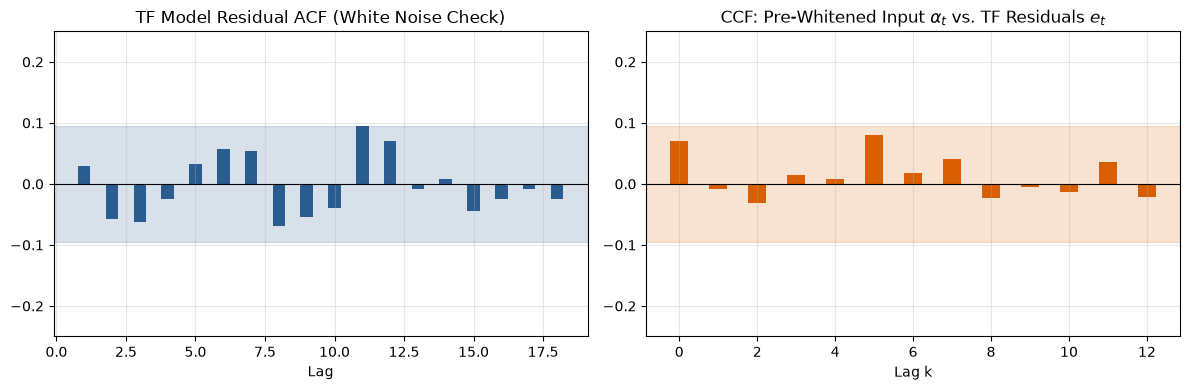

In [ ]:
# STEP 3 - ESTIMATE TRANSFER FUNCTION + AR(1) NOISE & DIAGNOSTICS

# Stationary series: dY_t = (1 - B) ln(Price_t), dX_t = (1 - B)(1 - B^12) BoxCox(Ground_t)
dY = df["Y_price"].diff(1)
dX = df["X_ground"].diff(1).diff(12)

tf_df = pd.DataFrame({
    "dY": dY,
    "dX_lag9": dX.shift(9),
    "dX_lag10": dX.shift(10),
}).dropna()

# 1. Univariate Benchmark ARIMA(1,1,0) on Y_price (same estimation window)
uni_mod = sm.tsa.SARIMAX(
    df["Y_price"].loc[tf_df.index],
    order=(1, 1, 0),
    trend="n"
).fit(disp=False)

# 2. Transfer Function Model (b=9, s=1, r=0) + AR(1) Noise
tf_mod = sm.tsa.SARIMAX(
    tf_df["dY"],
    exog=tf_df[["dX_lag9", "dX_lag10"]],
    order=(1, 0, 0),
    trend="n"
).fit(disp=False)

print("=== Model Comparison: Univariate ARIMA(1,1,0) vs. Transfer Function (b=9, s=1, r=0) ===")
print(f"Univariate ARIMA(1,1,0)             | AIC = {uni_mod.aic:8.2f} | BIC = {uni_mod.bic:8.2f}")
print(f"Transfer Function (b=9, s=1, r=0)   | AIC = {tf_mod.aic:8.2f} | BIC = {tf_mod.bic:8.2f}\n")
print(tf_mod.summary().tables[1])

# Residual White Noise & Cross-Correlation Independence Check (Step 3 Diagnostics)
resid_tf = tf_mod.resid
lb_tf = acorr_ljungbox(resid_tf, lags=[6, 12, 18, 24], return_df=True)
lb_tf.columns = ["ChiSq (Q)", "Pr > ChiSq"]
print("\n[Diagnostic 1] Residual Autocorrelation Check for White Noise:")
print(lb_tf.to_string())

# Check CCF between pre-whitened input alpha_t and TF model residuals e_t
alpha_aligned = alpha_t.loc[resid_tf.index]
ccf_resid = [alpha_aligned.shift(k).corr(resid_tf) for k in range(0, 13)]
se_tf = 1.96 / np.sqrt(len(resid_tf))
print(f"\n[Diagnostic 2] Input-Residual Cross-Correlation Check (95% Band = +/- {se_tf:.4f}):")
for k, val in enumerate(ccf_resid):
    print(f"Lag k = {k:2d}: CCF(alpha_t, e_t) = {val:+.4f}")

# Plot Residual Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lags_diag = np.arange(1, 19)
acf_e = acf(resid_tf, nlags=18, fft=False)[1:]
axes[0].bar(lags_diag, acf_e, width=0.45, color="#2b5c8f")
axes[0].axhspan(-se_tf, se_tf, color="#2b5c8f", alpha=0.18)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("TF Model Residual ACF (White Noise Check)")
axes[0].set_xlabel("Lag")
axes[0].set_ylim(-0.25, 0.25)
axes[0].grid(True, alpha=0.3)

axes[1].bar(np.arange(0, 13), ccf_resid, width=0.45, color="#d95f02")
axes[1].axhspan(-se_tf, se_tf, color="#d95f02", alpha=0.18)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("CCF: Pre-Whitened Input $\\alpha_t$ vs. TF Residuals $e_t$")
axes[1].set_xlabel("Lag k")
axes[1].set_ylim(-0.25, 0.25)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== Out-of-Sample Forecast Accuracy (12-Month Holdout: 2025-10 to 2026-09) ===
Univariate ARIMA(1,1,0)           | RMSE = $0.1858/bu | MAE = $0.1272/bu | MAPE = 2.27%
Transfer Function (b=9, s=1, r=0) | RMSE = $0.1875/bu | MAE = $0.1284/bu | MAPE = 2.29%


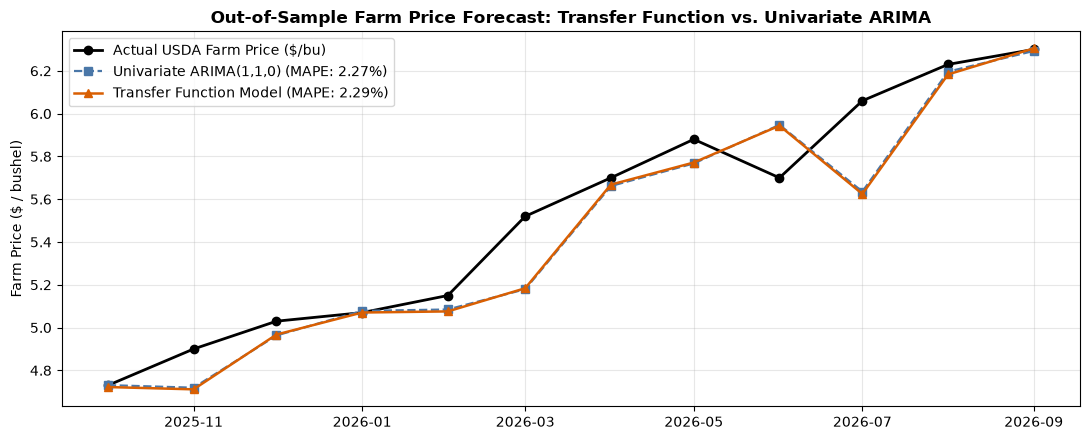

In [ ]:
# STEP 4 - OUT-OF-SAMPLE ROLLING FORECAST COMPARISON (LAST 12 MONTHS)

# Because b = 9 months, X_{t-9} and X_{t-10} are ALREADY KNOWN up to 9 months ahead!
test_horizon = 12
train_end = len(tf_df) - test_horizon

actual_price = df["Farm_Price"].loc[tf_df.index[train_end:]]
prev_log_price = df["Y_price"].shift(1).loc[tf_df.index[train_end:]]

# 1-Step-Ahead Out-of-Sample Forecasts on Last 12 Months
pred_dY_uni = []
pred_dY_tf = []

for i in range(train_end, len(tf_df)):
    # Fit Univariate AR(1) on dY up to i-1
    m_u = sm.tsa.SARIMAX(tf_df["dY"].iloc[:i], order=(1, 0, 0), trend="n").fit(disp=False)
    pred_dY_uni.append(m_u.forecast(steps=1).iloc[0])

    # Fit Transfer Function (b=9, s=1) + AR(1) up to i-1
    m_tf = sm.tsa.SARIMAX(
        tf_df["dY"].iloc[:i],
        exog=tf_df[["dX_lag9", "dX_lag10"]].iloc[:i],
        order=(1, 0, 0),
        trend="n"
    ).fit(disp=False)
    pred_dY_tf.append(m_tf.forecast(steps=1, exog=tf_df[["dX_lag9", "dX_lag10"]].iloc[i:i+1]).iloc[0])

# Convert predicted log-differences back to $/bushel price scale
fc_price_uni = np.exp(prev_log_price.values + np.array(pred_dY_uni))
fc_price_tf = np.exp(prev_log_price.values + np.array(pred_dY_tf))

def calc_metrics(y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return rmse, mae, mape

rmse_u, mae_u, mape_u = calc_metrics(actual_price.values, fc_price_uni)
rmse_t, mae_t, mape_t = calc_metrics(actual_price.values, fc_price_tf)

print("=== Out-of-Sample Forecast Accuracy (12-Month Holdout: 2025-10 to 2026-09) ===")
print(f"Univariate ARIMA(1,1,0)           | RMSE = ${rmse_u:.4f}/bu | MAE = ${mae_u:.4f}/bu | MAPE = {mape_u:.2f}%")
print(f"Transfer Function (b=9, s=1, r=0) | RMSE = ${rmse_t:.4f}/bu | MAE = ${mae_t:.4f}/bu | MAPE = {mape_t:.2f}%")

# Plot Actual vs Forecasted Farm Price
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(actual_price.index, actual_price.values, "o-", color="black", lw=2, label="Actual USDA Farm Price ($/bu)")
ax.plot(actual_price.index, fc_price_uni, "s--", color="#4a77a8", lw=1.6, label=f"Univariate ARIMA(1,1,0) (MAPE: {mape_u:.2f}%)")
ax.plot(actual_price.index, fc_price_tf, "^-", color="#d95f02", lw=1.8, label=f"Transfer Function Model (MAPE: {mape_t:.2f}%)")
ax.set_title("Out-of-Sample Farm Price Forecast: Transfer Function vs. Univariate ARIMA", fontsize=12, fontweight="bold")
ax.set_ylabel("Farm Price ($ / bushel)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()